# 4. Why the learners fall short

Notebook 3 measured *how far* each learner is from the optimum. Because the optimal values $V^\ast$ and $Q^\ast$ are known exactly, we can also look inside the learned tables and ask *why*. This notebook

1. measures how much optimism is left in each Q-table after training;
2. demonstrates, live, that potential-based shaping is the same thing as a different initial Q-table (Wiewiora, 2003);
3. shows that the initial value, not the reward, is what decides the tabular learners' final quality, and locates the best initial value from $V^\ast$.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from scipy import stats
from IPython.display import Image
from mdp import StoreMDP
from evaluation import Reference
import tabular, analyze
runs = analyze.load()

## 4.1 Optimism left in the table

For a tabular learner, the *value bias* is $\mathbb{E}_{s\sim d^{\pi^\ast}}[\max_a Q(s,a) - V^\ast_{R}(s)]$: how far the learned values sit above the true optimal values of the reward the agent trained on, on the states the optimal policy actually visits. All tables start at $Q_0 = 0$, which is above every true value here because the objective only ever charges.

In [2]:
out = []
for a in ["qlearning", "sarsa", "nstep_sarsa", "sarsa_lambda", "mc"]:
    for r in analyze.REWARDS:
        cell = runs[(a, r)]
        out.append({"learner": analyze.PLAIN[a], "reward": analyze.RLABEL[r],
                    "score": analyze.by_layout(cell, lambda q: q["final"]["score"]).mean(),
                    "value bias": analyze.by_layout(cell, lambda q: q["value_bias"]).mean(),
                    "states visited": analyze.by_layout(cell, lambda q: q["coverage"]).mean()})
pd.DataFrame(out).pivot(index="learner", columns="reward", values=["score", "value bias"]).round(2)

score                         value bias                 \
reward       Objective PBRS-d PBRS-ds Proposal  Objective PBRS-d PBRS-ds   
learner                                                                    
4-step Sarsa      0.56   0.61    0.67     0.68      12.92  10.61   25.72   
MC control        0.43   0.42    0.27     0.38     -24.80 -26.88  -18.09   
Q-Learning        0.23   0.22    0.17     0.27      39.23  36.45   52.26   
SARSA             0.40   0.37    0.46     0.48      36.90  33.67   49.86   
SARSA(λ)          0.63   0.66    0.65     0.73       7.25   5.02   16.53   

                       
reward       Proposal  
learner                
4-step Sarsa   -12.62  
MC control     -56.75  
Q-Learning      11.29  
SARSA            7.43  
SARSA(λ)       -15.85

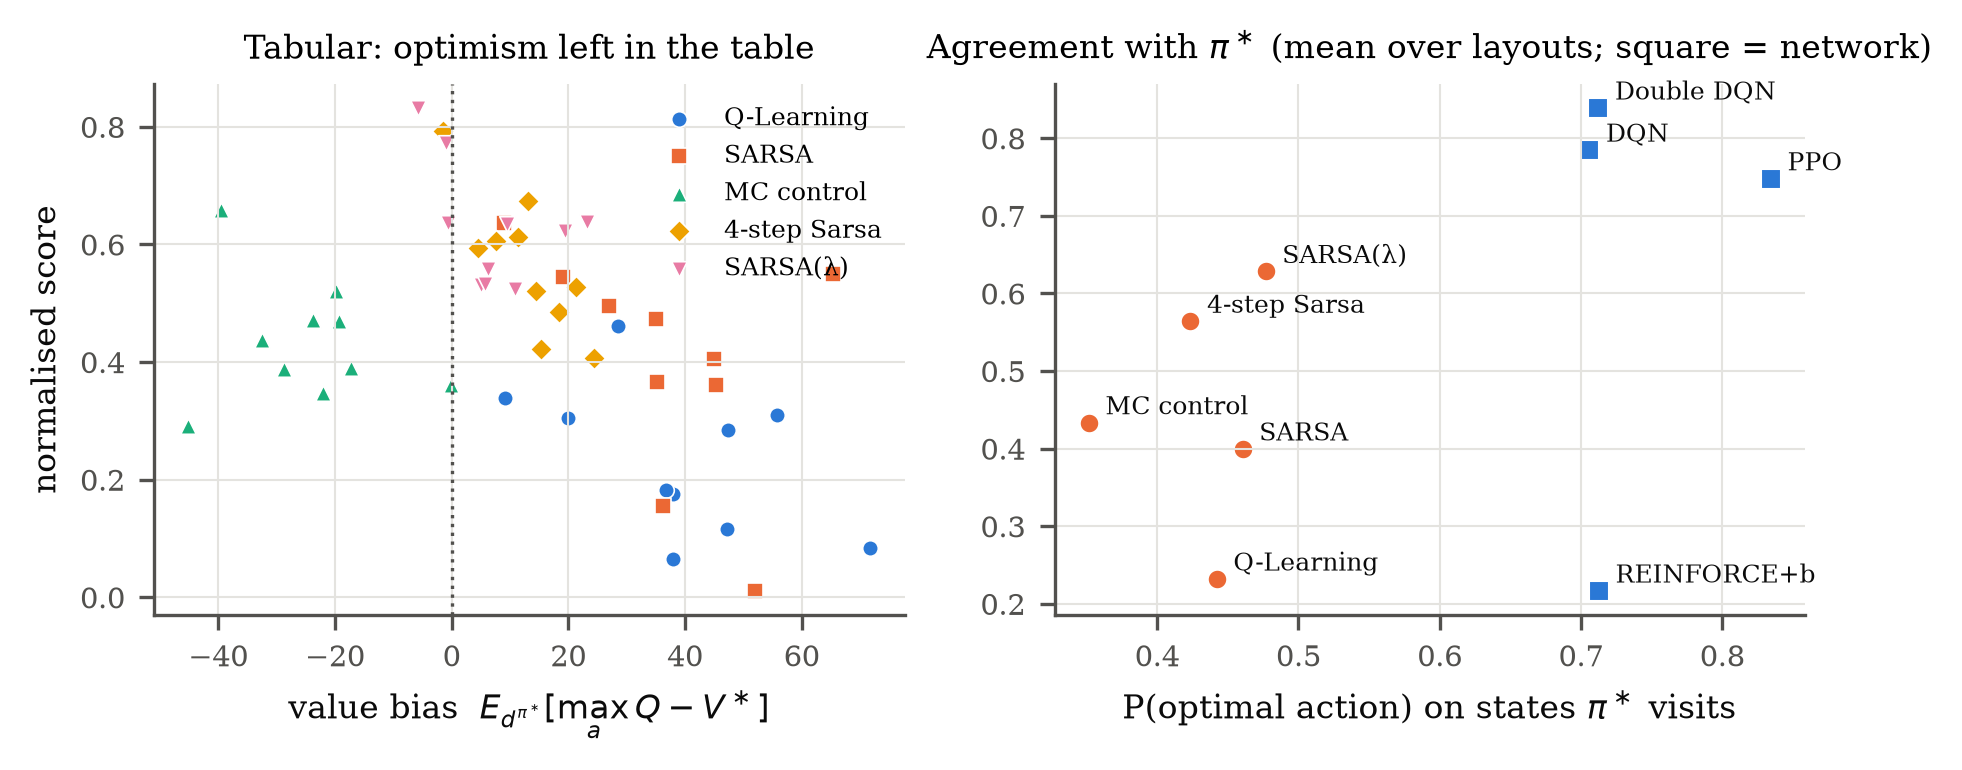

In [3]:
analyze.fig_diagnostics(runs, "objective")
Image(filename=str(ROOT / "results/figures/diagnostics_objective.png"), width=760)

After 120,000 steps the one-step learners still sit well above $V^\ast$: each update moves a value only $\alpha$ of the way toward a target that is itself too high, so the initial optimism drains out one backup at a time. Eligibility traces and multi-step targets spread each correction across many states and remove most of the bias. Monte Carlo has no bootstrapping at all and ends *below* $V^\ast$, because its targets are the returns of an exploring policy.

## 4.2 Shaping is initialisation (Wiewiora, 2003)

For tabular TD learners, adding $F = \gamma\Phi(s') - \Phi(s)$ to every reward is equivalent to starting from $Q_0(s,a) = \Phi(s)$ with no shaping: the two learners see the same experience and their tables differ by exactly $\Phi(s)$ at every step. Check it directly with the same random seed:

In [4]:
m = StoreMDP(0)
phi = 2.0 * m.phi["distance"]                       # the PBRS-d potential
for algo, episodes in [("sarsa", 600), ("qlearning", 40)]:
    Q_shaped, v1 = tabular.train(algo, m, reward="pbrs", episodes=episodes)
    Q_init, v2 = tabular.train(algo, m, reward="objective", episodes=episodes, q_init=phi)
    print(f"{algo:9s} {episodes} runs: identical visits {np.array_equal(v1, v2)},"
          f" max |Q_shaped - (Q_init - Phi)| = {np.abs(Q_shaped - (Q_init - phi[:, None])).max():.1e}")

sarsa     600 runs: identical visits True, max |Q_shaped - (Q_init - Phi)| = 1.1e-13
qlearning 40 runs: identical visits True, max |Q_shaped - (Q_init - Phi)| = 4.3e-14


(Q-Learning is shown for 40 runs: beyond that, rounding errors of order $10^{-14}$ eventually tip one exact tie in an argmax the other way and the two runs part company. SARSA happens to stay identical for the full 600 runs.)

So for a Q-table, PBRS-d is nothing more than lowering the initial value by twice the distance to the target shelf, at most 12. Set against an optimism of roughly 50, that is too small to matter, which is why PBRS-d barely changed the tabular scores in notebook 3.

## 4.3 The optimism gap of each reward

If initial optimism is the bottleneck, rewards should help in proportion to how much they shrink the gap between $Q_0 = 0$ and the true values $V^\ast_R$ of the reward:

In [5]:
gap = {r: [] for r in analyze.REWARDS}
for L in range(10):
    mm = StoreMDP(L); ref = Reference(mm)
    for r in analyze.REWARDS:
        V, *_ = mm.value_iteration(mm.reward(r))
        gap[r].append(float(ref.star["occupancy"] @ (0 - V)))
pd.DataFrame({analyze.RLABEL[r]: {"optimism gap  0 - V*_R": np.mean(gap[r]),
                                  **{analyze.PLAIN[a]: analyze.by_layout(runs[(a, r)], lambda q: q["final"]["score"]).mean()
                                     for a in ["qlearning", "sarsa", "nstep_sarsa", "sarsa_lambda"]}}
              for r in analyze.REWARDS}).round(3)

,Proposal,Objective,PBRS-d,PBRS-ds
optimism gap 0 - V*_R,19.498,54.869,50.513,68.305
Q-Learning,0.267,0.232,0.223,0.169
SARSA,0.484,0.400,0.372,0.461
4-step Sarsa,0.679,0.564,0.607,0.665
SARSA(λ),0.727,0.629,0.659,0.646


The Proposal reward has by far the smallest gap, because its restock and closer bonuses lift the true values toward zero, and it is the reward the TD learners did best with. The test below makes the causal version of this claim: keep the Objective reward and change only $Q_0$.

## 4.4 Changing only the initial value

In [6]:
inits = [0, -50, -100, -150, -200, -300]
tab = ["qlearning", "sarsa", "nstep_sarsa", "sarsa_lambda", "mc"]
sweep = {}
for q in inits:
    cells = runs if q == 0 else analyze.load(tag=f"init{q}")
    sweep[q] = {a: analyze.ci95(analyze.by_layout(cells[(a, "objective")], lambda r: r["final"]["score"])) for a in tab}
pd.DataFrame({analyze.PLAIN[a]: {q: f"{sweep[q][a][0]:.3f} ± {sweep[q][a][1]:.3f}" for q in inits} for a in tab})

,Q-Learning,SARSA,4-step Sarsa,SARSA(λ),MC control
0,0.232 ± 0.091,0.400 ± 0.136,0.564 ± 0.084,0.629 ± 0.074,0.434 ± 0.075
-50,0.388 ± 0.150,0.471 ± 0.153,0.612 ± 0.101,0.702 ± 0.081,0.371 ± 0.118
-100,0.545 ± 0.200,0.638 ± 0.130,0.675 ± 0.134,0.751 ± 0.130,0.367 ± 0.168
-150,0.686 ± 0.031,0.720 ± 0.039,0.750 ± 0.040,0.794 ± 0.024,0.347 ± 0.189
-200,0.527 ± 0.028,0.570 ± 0.042,0.656 ± 0.059,0.701 ± 0.047,0.408 ± 0.151
-300,0.423 ± 0.046,0.385 ± 0.018,0.479 ± 0.024,0.517 ± 0.035,0.396 ± 0.103


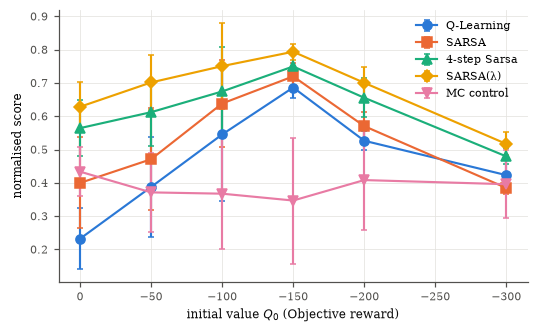

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for i, a in enumerate(tab):
    m_ = [sweep[q][a][0] for q in inits]; h_ = [sweep[q][a][1] for q in inits]
    ax.errorbar(inits, m_, yerr=h_, marker=analyze.MARKERS[i], color=analyze.COLORS[i], capsize=2, label=analyze.PLAIN[a])
ax.set_xlabel("initial value $Q_0$ (Objective reward)"); ax.set_ylabel("normalised score"); ax.invert_xaxis()
ax.legend(frameon=False, fontsize=7); plt.show()

### Why an initial value below zero helps, and why too far below hurts

All true values here are negative. Whatever part of $Q_0$ a pair $(s,a)$ has not yet overwritten is largest for the pairs tried least. Starting above every true value makes exactly those pairs look best, so the greedy policy is pulled toward the actions it knows least about. Starting far below makes them look worst, which is harmless for that choice, but then the policy commits to whatever it tried early and the values must climb a long way, one backup at a time. Count, during training, how often the greedy action is the least-tried action in its state, and how often the greedy action was tried:

In [8]:
import retail_env
counts = {}
class CountingEnv(retail_env.RetailRestockEnv):
    def step(self, a):
        k = (self.state_key(), int(a)); counts[k] = counts.get(k, 0) + 1
        return super().step(a)
tabular.RetailRestockEnv = CountingEnv           # count (state, action) visits during training
rows = []
for algo in ("qlearning", "sarsa", "sarsa_lambda"):
    for q0 in (0.0, -150.0, -300.0):
        least, tries, score = [], [], []
        for L in range(5):
            counts.clear(); mm = StoreMDP(L); ref = Reference(mm)
            Q, _ = tabular.train(algo, mm, reward="objective", q_init=q0)
            pi = Q.argmax(1); e = mm.episode_metrics(pi); occ = e["occupancy"]
            N = np.zeros((mm.nS, 7))
            for (s, a), c in counts.items(): N[mm.index[s], a] = c
            is_least = (N[np.arange(mm.nS), pi] == N.min(1)) & (N.min(1) < N.max(1))
            least.append(occ @ is_least); tries.append(occ @ N[np.arange(mm.nS), pi]); score.append(ref.score(e["objective"]))
        rows.append({"learner": analyze.PLAIN[algo], "Q0": q0, "score": np.mean(score),
                     "P(greedy = least tried)": np.mean(least), "tries of greedy action": np.mean(tries)})
tabular.RetailRestockEnv = retail_env.RetailRestockEnv
pd.DataFrame(rows).round(3)

,learner,Q0,score,P(greedy = least tried),tries of greedy action
0,Q-Learning,0.0,0.273,0.157,212.684
1,Q-Learning,-150.0,0.701,0.001,698.219
2,Q-Learning,-300.0,0.419,0.000,1671.455
3,SARSA,0.0,0.519,0.089,284.930
4,SARSA,-150.0,0.715,0.027,543.280
5,SARSA,-300.0,0.381,0.006,2470.688
6,SARSA(λ),0.0,0.682,0.110,309.614
7,SARSA(λ),-150.0,0.803,0.001,529.965
8,SARSA(λ),-300.0,0.516,0.000,1056.042


With $Q_0 = 0$ the greedy action is the least-tried action in its state 9--16% of the time; at $-150$ almost never. At $-300$ it is never the least-tried, but it has been tried thousands of times: the policy has locked onto early choices instead of comparing alternatives. The best constant sits between the two failure modes.

### Where is the best value, relative to $V^\ast$?

In [9]:
stats_ = []
for L in range(10):
    mm = StoreMDP(L); ref = Reference(mm); V = ref.V_star
    d_rand = mm.episode_metrics(np.full((mm.nS, 7), 1 / 7))["occupancy"]
    stats_.append({"max V*": V.max(), "V* on states pi* visits": ref.star["occupancy"] @ V,
                   "median V*": np.median(V), "V* on states a random explorer visits": d_rand @ V, "min V*": V.min()})
pd.DataFrame(stats_).mean().round(1)

max V*                                   -18.6
V* on states pi* visits                  -54.9
median V*                                -63.0
V* on states a random explorer visits   -137.0
min V*                                  -197.0
dtype: float64

$Q_0 = 0$ is above the largest optimal value of any state, so every value starts too high; $-300$ is below the smallest, so every value starts too low. The best constant, $-150$, lies close to the average optimal value of the states an exploring agent spends its time in (about $-137$). This is an observed coincidence, not a derived rule. Note also that at $Q_0=-150$ the trained tables still sit well *below* $V^\ast$ on the states the optimal policy visits (value bias $-67$ to $-82$): what matters for the greedy policy is how the leftover error is spread across actions, not how accurate the values are.

The location of the peak is read off the oracle here. Without a model it would have to be estimated, for example from the returns of a simple hand-written policy; that estimate was not tested in this project.

## 4.5 Does the same hold for DQN?

A Q-network also starts with outputs near zero. Setting the output bias so that every initial value is $-150$:

In [10]:
ini = analyze.load(tag="init-150")
for a in ("dqn", "double_dqn"):
    q = analyze.by_layout(ini[(a, "objective")], lambda r: r["final"]["score"])
    b = analyze.by_layout(runs[(a, "objective")], lambda r: r["final"]["score"])
    p_ = analyze.by_layout(runs[(a, "proposal")], lambda r: r["final"]["score"])
    print(f"{analyze.PLAIN[a]:10s} Objective, Q0=0: {b.mean():.3f}   Objective, Q0=-150: {q.mean():.3f} "
          f"(paired p = {stats.ttest_rel(q, b).pvalue:.3f})   Proposal: {p_.mean():.3f}")

DQN        Objective, Q0=0: 0.785   Objective, Q0=-150: 0.793 (paired p = 0.797)   Proposal: 0.957
Double DQN Objective, Q0=0: 0.839   Objective, Q0=-150: 0.785 (paired p = 0.025)   Proposal: 0.960


No. A network shares its parameters across all states, so a few hundred updates rescale every output at once and no state keeps its initial value for long. For DQN the gain from the Proposal reward is therefore a real effect of its extra terms, not of initialisation. The next cell separates the two terms.

In [11]:
cols = ["objective", "objective_restock", "objective_closer", "proposal", "pbrs", "pbrs_stock"]
out = {}
for a in ["sarsa_lambda", "dqn"]:
    base = analyze.by_layout(runs[(a, "objective")], lambda q: q["final"]["score"])
    row = {}
    for c in cols:
        sc = analyze.by_layout(runs[(a, c)], lambda q: q["final"]["score"])
        p_ = stats.ttest_rel(sc, base).pvalue if c != "objective" else 1.0
        row[c] = f"{sc.mean():.3f}{' *' if p_ < 0.05 else ''}"
    out[analyze.PLAIN[a]] = row
pd.DataFrame(out).T

,objective,objective_restock,objective_closer,proposal,pbrs,pbrs_stock
SARSA(λ),0.629,0.708 *,0.684 *,0.727 *,0.659,0.646
DQN,0.785,0.905 *,0.884 *,0.957 *,0.844,0.855 *


(* paired $p<0.05$ against the Objective reward.) Both proposal terms help DQN, roughly additively, and their potential-based forms recover about half of the gain while provably leaving the optimal policy alone.